# GROS BROWNIANO — ¿el movimiento es browniano? (sin restar deriva)

Video de otro grupo: `C:\datos_pinzas\OTROS GRUPOS\GROS BROWNIANO\browngod4_0.avi` (AVI Motion-JPEG, 600 cuadros de 1280 × 1024, 15 cuadros por segundo, 40 s). Las trayectorias salen de `TouchDesigner/bloques/_lote.py` con los **parámetros por defecto** de los bloques y están en `datos/GROS BROWNIANO/`. Los pasos intermedios del análisis de imagen están en `figuras/GROS BROWNIANO/pasos/`.

**Acá no se resta la deriva**: las posiciones se usan tal como salen del tracking. Con una deriva de velocidad $v$ se espera $\mathrm{MSD}(\tau) = 4D\tau + v^2\tau^2 + 4\sigma^2$, es decir, un MSD que se curva hacia arriba, y desplazamientos con media distinta de cero.

Se miran las mismas tres cosas que en `BROWNIANO 1.ipynb`:

1. si el MSD crece **lineal** con el retardo;
2. si los desplazamientos a un retardo fijo son **gaussianos**, con media cero e iguales en $x$ y en $y$;
3. si un paso **no depende** del anterior.

Dos límites de los datos:

- **Tiempo nominal.** El AVI no trae el tiempo de cada cuadro: se usa el fps del archivo (15.001).
- **Sin escala.** Todo está en px; el AVI está comprimido a 8 bits.

In [1]:
from trayectorias import *
from scipy import stats

# estilo de ESTILO_FIGURAS.md (raíz del repo)
plt.style.use("seaborn-v0_8")
fs = 14
plt.rcParams.update({"font.family": "serif", "font.size": fs, "axes.labelsize": fs,
                     "xtick.labelsize": fs, "ytick.labelsize": fs, "legend.fontsize": fs,
                     "mathtext.default": "regular", "mathtext.fontset": "cm", "legend.frameon": True})
SERIE1, SERIE2, AJUSTE = "#2A9D8F", "#E76F51", "#264653"

DATOS = os.path.join(RAIZ, "datos", "GROS BROWNIANO")        # RAIZ = pinzas ópticas/
FIGURAS = os.path.join(RAIZ, "figuras", "GROS BROWNIANO")
os.makedirs(FIGURAS, exist_ok=True)

RESTAR_DERIVA = False   # False: las posiciones se usan tal como salen del tracking
LARGO_MIN = 300      # cuadros medidos (20 s): las trayectorias más cortas no entran
MAX_LAG = 30         # retardo máximo del MSD, en cuadros (2 s)
N_AJUSTE = 4         # retardos que se usan para ajustar D
ALFA_LIBRE = 0.5     # pendiente log-log del MSD por encima de la cual una partícula es libre
VENTANA = 101        # pasos (6.7 s) con los que se calcula la sigma local


def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(os.path.join(FIGURAS, nombre + ".pdf"), bbox_inches="tight")
    fig.savefig(os.path.join(FIGURAS, nombre + ".png"), bbox_inches="tight", dpi=300)


datos = cargar(DATOS)
tr = datos["tr"]
n_total, n_colision = len(tr), int(tr.colision.sum())
tr.loc[tr.colision == 1, ["x_px", "y_px"]] = np.nan       # dos beads muy cerca: posición poco confiable
t, X, Y, ids, u = matrices(datos, largo_min=LARGO_MIN)
print("%d cuadros, %.0f s | %d trayectorias en total, %d con más de %d cuadros | unidad: %s"
      % (len(t), t[-1] - t[0], tr.particula.nunique(), len(ids), LARGO_MIN, u))
print("puntos descartados por colisión: %d de %d" % (n_colision, n_total))

600 cuadros, 40 s | 24 trayectorias en total, 12 con más de 300 cuadros | unidad: px
puntos descartados por colisión: 272 de 8039


## 1. Trayectorias y MSD de cada una

Sin restar nada. La columna *velocidad media* es la pendiente de la recta $x(t)$, $y(t)$ de cada trayectoria: se informa para saber cuánta deriva hay, pero **no se resta**. $\alpha$ es la pendiente del MSD en log-log: cerca de 1 es difusión libre, por encima de 1 hay deriva, por debajo de 0.5 la partícula está confinada o pegada.

In [2]:
Xs, Ys = sin_deriva_por_particula(t, X, Y) if RESTAR_DERIVA else (X, Y)
vx, vy = velocidades(t, X, Y)
m = msd(t, Xs, Ys, MAX_LAG)
alfa = pendiente_loglog(m)
tabla = coeficientes_D(m, n_puntos=N_AJUSTE)
libres = alfa > ALFA_LIBRE
tabla = pd.DataFrame({"partícula": ids, "cuadros": np.isfinite(X).sum(0), "velocidad media [px/s]": np.hypot(vx, vy),
                      "alfa": alfa, "D [px²/s]": tabla.D.values, "ordenada [px²]": tabla.ordenada.values,
                      "libre": libres})
print("libres: %d | confinadas: %d (partícula %s)"
      % (libres.sum(), (~libres).sum(), ", ".join(map(str, ids[~libres])) or "-"))
tabla.round(2)

libres: 12 | confinadas: 0 (partícula -)


,partícula,cuadros,velocidad media [px/s],alfa,D [px²/s],ordenada [px²],libre
0,0,600,2.52,0.98,17.75,-1.88,True
1,1,600,1.29,1.03,14.98,-0.54,True
2,2,423,1.55,1.03,17.77,-0.46,True
3,3,381,0.50,1.09,14.86,-0.94,True
4,4,600,1.94,1.04,22.01,-0.31,True
5,5,494,2.36,0.99,20.91,-0.66,True
6,6,600,2.52,1.20,21.11,-2.20,True
7,8,600,2.93,1.18,18.81,-1.46,True
8,9,600,2.89,1.09,18.62,-1.60,True
9,10,600,3.60,1.21,21.90,-1.96,True


## 2. MSD

Promedio de las trayectorias libres, pesado por la cantidad de pares de cada una. La barra de error es la dispersión entre trayectorias dividida por $\sqrt{N}$. La recta se ajusta a los primeros `N_AJUSTE` retardos (puntos llenos) y se extiende al resto (puntos huecos).

Como la deriva no está restada, se compara lo que el MSD se aparta de la recta con el término $v^2\tau^2$ que daría la velocidad media de cada trayectoria.

MSD del conjunto: D = 19.17 px²/s, ordenada = -1.18 px² 
pendiente log-log del MSD del conjunto (30 retardos): 1.10
recta extendida vs medido en tau = 2.0 s: 152.2 vs 175.6 px² (+15 %)
exceso sobre la recta en tau = 2.0 s: 23.5 px² | término de deriva v²·tau² con la velocidad de cada trayectoria: 21.4 px²
D por trayectoria: de 14.9 a 22.2 px²/s, media 19.0 ± 0.8 (dispersión/√N)


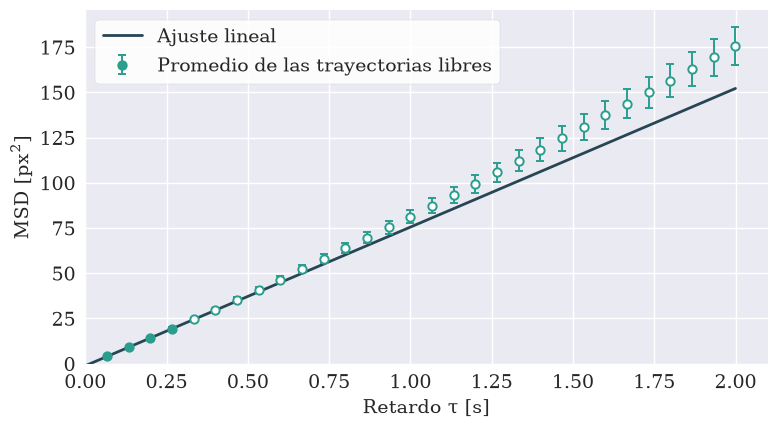

In [3]:
ml = columnas(m, libres)
prom, err = msd_conjunto(ml)
tau = m["tau"]
aj = libre.ajustar_msd(tau, prom, 0.0, n_puntos=N_AJUSTE)
pend_loglog = np.polyfit(np.log(tau), np.log(prom), 1)[0]
D_ind = tabla["D [px²/s]"][libres]

fig, ax = plt.subplots(figsize=(8, 4.5))
estilo = dict(fmt="o", ms=6, capsize=3, elinewidth=1.4, capthick=1.4, mew=1.4, color=SERIE1, mec=SERIE1, zorder=3)
ax.errorbar(tau[:N_AJUSTE], prom[:N_AJUSTE], err[:N_AJUSTE], mfc=SERIE1, label="Promedio de las trayectorias libres", **estilo)
ax.errorbar(tau[N_AJUSTE:], prom[N_AJUSTE:], err[N_AJUSTE:], mfc="white", **estilo)
tt = np.linspace(0, tau[-1], 100)
ax.plot(tt, 4 * aj["D"] * tt + aj["ordenada"], color=AJUSTE, lw=2, zorder=2, label="Ajuste lineal")
ax.set_xlabel(r"Retardo $\tau$ [s]")
ax.set_ylabel(r"MSD [px$^2$]")
ax.set_xlim(0, None); ax.set_ylim(0, None)
ax.legend(loc="upper left", facecolor="white", framealpha=0.9)
guardar(fig, "msd")

print("MSD del conjunto: D = %.2f px²/s, ordenada = %.2f px² " % (aj["D"], aj["ordenada"]))
print("pendiente log-log del MSD del conjunto (30 retardos): %.2f" % pend_loglog)
print("recta extendida vs medido en tau = %.1f s: %.1f vs %.1f px² (%+.0f %%)"
      % (tau[-1], 4 * aj["D"] * tau[-1] + aj["ordenada"], prom[-1],
         100 * (prom[-1] / (4 * aj["D"] * tau[-1] + aj["ordenada"]) - 1)))
v2 = np.mean(tabla["velocidad media [px/s]"][libres] ** 2)
print("exceso sobre la recta en tau = %.1f s: %.1f px² | término de deriva v²·tau² con la velocidad de cada trayectoria: %.1f px²"
      % (tau[-1], prom[-1] - (4 * aj["D"] * tau[-1] + aj["ordenada"]), v2 * tau[-1] ** 2))
print("D por trayectoria: de %.1f a %.1f px²/s, media %.1f ± %.1f (dispersión/√N)"
      % (D_ind.min(), D_ind.max(), D_ind.mean(), D_ind.std() / np.sqrt(len(D_ind))))

## 3. Histograma de desplazamientos

Desplazamientos entre cuadros consecutivos ($\tau$ = 0.067 s) de las trayectorias libres. Cada trayectoria tiene su propio $D$, así que cada desplazamiento se divide por la desviación estándar $\sigma$ de su trayectoria y de su eje antes de juntarlos; si no, mezclar partículas con $D$ distinto da colas anchas aunque cada una sea gaussiana.

6668 desplazamientos en x y 6668 en y, de 12 trayectorias
sigma por paso: de 1.15 a 1.72 px según la trayectoria
media del paso / sigma: como mucho 0.163 (cero = sin deriva)
sigma_y / sigma_x por trayectoria: 1.01 ± 0.10 (1 = isótropo)
media de todos los pasos normalizados: -0.057 en x, 0.087 en y (error 0.012)


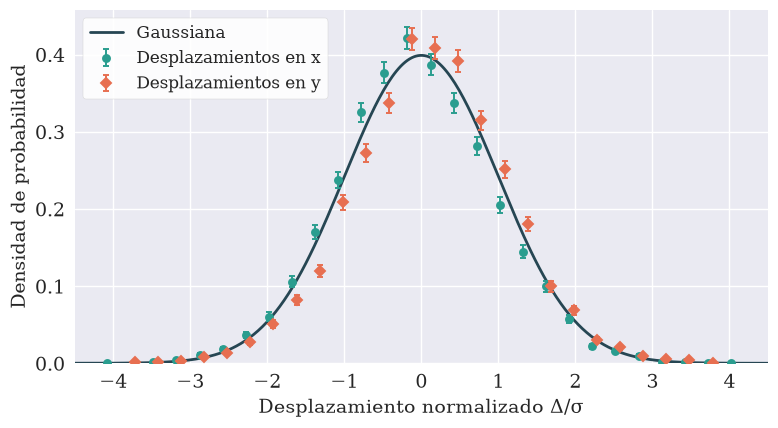

In [4]:
def pasos_normalizados(A, local=False):
    # pasos de un cuadro de cada trayectoria libre, divididos por su sigma (de toda la trayectoria o local)
    salida = []
    for k in np.flatnonzero(libres):
        d = A[1:, k] - A[:-1, k]
        d = d[np.isfinite(d)]
        s = pd.Series(d).rolling(VENTANA, center=True, min_periods=VENTANA // 3).std().values if local else d.std()
        salida.append(d / s)
    z = np.concatenate(salida)
    return z[np.isfinite(z)]


def densidad(z, bordes):
    # histograma normalizado: centros, densidad y su error (raíz de las cuentas); sin los bins vacíos
    n, _ = np.histogram(z, bordes)
    ancho = np.diff(bordes)
    ok = n > 0
    return (0.5 * (bordes[1:] + bordes[:-1]))[ok], (n / (len(z) * ancho))[ok], (np.sqrt(n) / (len(z) * ancho))[ok]


zx, zy = pasos_normalizados(Xs), pasos_normalizados(Ys)
u_ = np.linspace(-5.6, 5.6, 400)
gauss = np.exp(-u_ ** 2 / 2) / np.sqrt(2 * np.pi)

fig, ax = plt.subplots(figsize=(8, 4.5))
bordes = np.arange(-4.5, 4.51, 0.3)
marca = dict(ms=5, capsize=2, elinewidth=1.4, capthick=1.4, mew=1.4, zorder=3)
for z, color, fmt, corr, nombre in ((zx, SERIE1, "o", -0.03, "Desplazamientos en $x$"), (zy, SERIE2, "D", 0.03, "Desplazamientos en $y$")):
    cx, dens, e = densidad(z, bordes)
    ax.errorbar(cx + corr, dens, e, fmt=fmt, color=color, mfc=color, mec=color, label=nombre, **marca)
ax.plot(u_, gauss, color=AJUSTE, lw=2, zorder=2, label="Gaussiana")
ax.set_xlabel(r"Desplazamiento normalizado $\Delta/\sigma$")
ax.set_ylabel("Densidad de probabilidad")
ax.set_xlim(-4.5, 4.5); ax.set_ylim(0, None)
ax.legend(loc="upper left", fontsize=12, facecolor="white", framealpha=0.9)
guardar(fig, "histograma_desplazamientos")

sx = np.array([np.nanstd(np.diff(Xs[:, k])) for k in np.flatnonzero(libres)])
sy = np.array([np.nanstd(np.diff(Ys[:, k])) for k in np.flatnonzero(libres)])
mx = np.array([np.nanmean(np.diff(Xs[:, k])) for k in np.flatnonzero(libres)])
my = np.array([np.nanmean(np.diff(Ys[:, k])) for k in np.flatnonzero(libres)])
print("%d desplazamientos en x y %d en y, de %d trayectorias" % (len(zx), len(zy), libres.sum()))
print("sigma por paso: de %.2f a %.2f px según la trayectoria" % (min(sx.min(), sy.min()), max(sx.max(), sy.max())))
print("media del paso / sigma: como mucho %.3f (cero = sin deriva)" % np.max(np.abs(np.r_[mx / sx, my / sy])))
print("sigma_y / sigma_x por trayectoria: %.2f ± %.2f (1 = isótropo)" % ((sy / sx).mean(), (sy / sx).std()))
print("media de todos los pasos normalizados: %.3f en x, %.3f en y (error %.3f)" % (zx.mean(), zy.mean(), 1 / np.sqrt(len(zx))))

### Las colas

En escala lineal las colas no se ven. En escala logarítmica una gaussiana es una parábola, y cualquier exceso en las colas queda a la vista. Acá se juntan $x$ e $y$ y se comparan dos formas de normalizar: con la $\sigma$ de **toda** la trayectoria, y con la $\sigma$ **local** (la de los `VENTANA` pasos de alrededor, 6.7 s).

gaussiana: curtosis en exceso 0, |z| > 3 en 0.27 %, |z| > 4 en 0.006 %
(dividir por una sigma de 101 pasos baja la curtosis en 0.06 aunque el dato sea gaussiano)


,normalización,n,curtosis en exceso,error,|z| > 3 [%],|z| > 4 [%],p de KS
0,sin normalizar (px),13336,0.5037,0.0424,0.5174,0.0600,0.0010
1,sigma de toda la trayectoria,13336,0.3079,0.0424,0.4499,0.0225,0.0245
2,sigma local,13336,0.1722,0.0424,0.3974,0.0225,0.0996


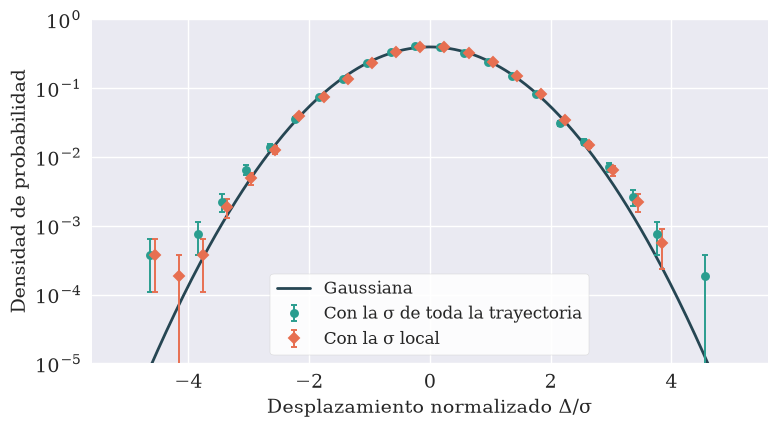

In [5]:
z_tray = np.r_[zx, zy]
z_local = np.r_[pasos_normalizados(Xs, local=True), pasos_normalizados(Ys, local=True)]
crudo = libre.desplazamientos(t, Xs[:, libres], Ys[:, libres], 1, libre.periodo_nominal(t))

fig, ax = plt.subplots(figsize=(8, 4.5))
bordes = np.arange(-5.6, 5.61, 0.4)
for z, color, fmt, corr, nombre in ((z_tray, SERIE1, "o", -0.04, r"Con la $\sigma$ de toda la trayectoria"),
                                    (z_local, SERIE2, "D", 0.04, r"Con la $\sigma$ local")):
    cx, dens, e = densidad(z, bordes)
    ax.errorbar(cx + corr, dens, e, fmt=fmt, color=color, mfc=color, mec=color, label=nombre, **marca)
ax.plot(u_, gauss, color=AJUSTE, lw=2, zorder=2, label="Gaussiana")
ax.set_yscale("log")
ax.set_xlabel(r"Desplazamiento normalizado $\Delta/\sigma$")
ax.set_ylabel("Densidad de probabilidad")
ax.set_xlim(-5.6, 5.6); ax.set_ylim(1e-5, 1)
ax.legend(loc="lower center", fontsize=12, facecolor="white", framealpha=0.9)
guardar(fig, "histograma_desplazamientos_log")

filas = []
for nombre, z in (("sin normalizar (px)", crudo / crudo.std()), ("sigma de toda la trayectoria", z_tray), ("sigma local", z_local)):
    filas.append({"normalización": nombre, "n": len(z), "curtosis en exceso": stats.kurtosis(z),
                  "error": np.sqrt(24 / len(z)), "|z| > 3 [%]": 100 * np.mean(np.abs(z) > 3),
                  "|z| > 4 [%]": 100 * np.mean(np.abs(z) > 4), "p de KS": stats.kstest(z / z.std(), "norm").pvalue})
print("gaussiana: curtosis en exceso 0, |z| > 3 en 0.27 %, |z| > 4 en 0.006 %")
print("(dividir por una sigma de %d pasos baja la curtosis en %.2f aunque el dato sea gaussiano)" % (VENTANA, 6 / (VENTANA + 1)))
pd.DataFrame(filas).round(4)

### Cuánto cambia el tamaño del paso a lo largo de una trayectoria

Si la $\sigma$ de los pasos cambia con el tiempo (la partícula sube o baja, se desenfoca), juntar toda la trayectoria mezcla gaussianas de distinto ancho. Eso es lo que da las colas de la curva verde.

In [6]:
filas = []
for k in np.flatnonzero(libres):
    d = np.diff(Xs[:, k]); d = d[np.isfinite(d)]
    s = pd.Series(d).rolling(VENTANA, center=True, min_periods=VENTANA // 3).std().dropna()
    filas.append({"partícula": ids[k], "sigma_x de toda la trayectoria [px]": d.std(),
                  "sigma_x local mínima [px]": s.min(), "sigma_x local máxima [px]": s.max(), "máx / mín": s.max() / s.min()})
pd.DataFrame(filas).round(2)

,partícula,sigma_x de toda la trayectoria [px],sigma_x local mínima [px],sigma_x local máxima [px],máx / mín
0,0,1.29,1.06,1.53,1.44
1,1,1.28,1.01,1.45,1.44
2,2,1.36,1.20,1.47,1.23
3,3,1.24,1.06,1.34,1.26
4,4,1.72,1.30,2.07,1.59
5,5,1.65,1.29,2.04,1.58
6,6,1.30,1.14,1.49,1.31
7,8,1.29,0.97,1.56,1.61
8,9,1.39,1.16,1.57,1.36
9,10,1.30,1.03,1.53,1.48


## 4. ¿Un paso depende del anterior?

En un browniano puro la correlación entre un paso y el siguiente es cero. La ordenada $a$ del MSD ($\mathrm{MSD} = a + 4D\tau$) dice cuánto se aparta: se espera $r = -a / \left(2\,(a + 4D\tau)\right)$.

- $a > 0$ (ruido de localización): correlación **negativa**.
- $a < 0$ (la cámara promedia el movimiento durante la exposición): correlación **positiva**.

Esta cuenta **no es una prueba independiente** del MSD: la correlación entre pasos y la ordenada son la misma información.

In [7]:
dt = libre.periodo_nominal(t)
filas = []
for k in np.flatnonzero(libres):
    r = []
    for A in (Xs, Ys):
        d = np.diff(A[:, k])
        ok = np.isfinite(d[:-1]) & np.isfinite(d[1:])
        r.append(np.corrcoef(d[:-1][ok], d[1:][ok])[0, 1])
    D, a = tabla["D [px²/s]"][k], tabla["ordenada [px²]"][k]
    filas.append({"partícula": ids[k], "correlación medida": np.mean(r), "esperada por la ordenada": -a / (2 * (a + 4 * D * dt)),
                  "error": 1 / np.sqrt(ok.sum())})
corr = pd.DataFrame(filas)
dif = corr["correlación medida"] - corr["esperada por la ordenada"]
print("correlación medida: media %.3f | diferencia medida − esperada: media %.3f, máxima %.3f"
      % (corr["correlación medida"].mean(), dif.mean(), dif.abs().max()))
print("ordenada del MSD del conjunto: %.2f px²; si fuera solo exposición, W = %.3f s (%.2f del período entre cuadros)"
      % (aj["ordenada"], -3 * aj["ordenada"] / (4 * aj["D"]), -3 * aj["ordenada"] / (4 * aj["D"]) / dt))
for k in np.flatnonzero(~libres):       # si no se mueve, el paso es puro ruido: sigma = desvío del paso / raíz de 2
    print("partícula %d (confinada): ruido de localización como mucho %.2f px en x y %.2f px en y"
          % (ids[k], np.nanstd(np.diff(Xs[:, k])) / np.sqrt(2), np.nanstd(np.diff(Ys[:, k])) / np.sqrt(2)))
corr.round(3)

correlación medida: media 0.142 | diferencia medida − esperada: media -0.018, máxima 0.119
ordenada del MSD del conjunto: -1.18 px²; si fuera solo exposición, W = 0.046 s (0.69 del período entre cuadros)


,partícula,correlación medida,esperada por la ordenada,error
0,0,0.228,0.330,0.041
1,1,0.125,0.078,0.041
2,2,0.097,0.054,0.049
3,3,0.127,0.157,0.052
4,4,0.017,0.028,0.041
5,5,0.132,0.067,0.045
6,6,0.200,0.320,0.041
7,8,0.196,0.205,0.041
8,9,0.196,0.238,0.041
9,10,0.201,0.252,0.041


## Conclusión

**Las partículas se mueven como un browniano con una deriva encima**, y como la deriva no está restada, se ve en las tres pruebas:

1. **MSD: lineal al principio, después se curva hacia arriba.** A 2 s el promedio queda 15 % por encima de la recta ajustada en los primeros 0.27 s: 23.5 px² de más. El término $v^2\tau^2$ con la velocidad media de cada trayectoria (de 0.5 a 3.6 px/s) da 21.4 px², casi lo mismo. Del tramo inicial sale $D$ = 19.2 px²/s.
2. **Desplazamientos casi gaussianos, pero corridos del cero.** La media de los pasos normalizados es −0.057 en $x$ y +0.087 en $y$ (error 0.012): es la deriva. El ancho es el mismo en $x$ y en $y$ ($\sigma_y/\sigma_x$ = 1.01 ± 0.10). Queda un exceso chico de pasos grandes: curtosis en exceso 0.31 ± 0.04 con la $\sigma$ de toda la trayectoria y 0.17 ± 0.04 con la $\sigma$ local, y 0.40 % de los pasos más allá de 3$\sigma$ contra 0.27 % de una gaussiana.
3. **Los pasos consecutivos están correlacionados en positivo**: 0.14 en promedio (de 0.00 a 0.23 según la trayectoria). Es lo que corresponde a la ordenada negativa del MSD (−1.18 px²).

A diferencia de BROWNIANO 1, acá $D$ es parecido en todas las trayectorias: de 14.9 a 22.2 px²/s, media 19.0 ± 0.8.

Lo que este análisis **no** alcanza a decir:

- **De dónde sale la correlación positiva.** Es lo que daría una exposición de unas 0.7 veces el período entre cuadros (la cámara promedia el movimiento), pero la exposición de este video no se conoce. Una deriva que cambia despacio también suma correlación positiva.
- **Si el exceso de pasos grandes es físico** o viene del tracking o de la compresión del AVI.
- **Si $D$ es el que corresponde** al tamaño de las beads: no hay escala.

Cuánto dato entró: de 24 trayectorias, 12 tienen más de 300 cuadros (20 s) y las 12 son libres. Se descartaron 272 de 8039 puntos por colisión. Los parámetros de detección son los por defecto; los pasos intermedios muestran que con ellos las beads se detectan bien.
